In [1]:
%pip install matplotlib pandas scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore')
%matplotlib inline

In [4]:
# Load your student interaction dataset (e.g., expanded_data_chat.csv)
df = pd.read_csv('expanded_data_chat.csv')

print(f'Dataset Shape: {df.shape}')
df.head()

Dataset Shape: (1322, 10)


,Conversation ID,User ID,Timestamp,User Message,Intent,Intent Confidence,Topic,Sentiment Score,Sentiment Label,Bot Response
0,conv_0001,user_0001,2026-09-01T08:05:12,How do I add a course to my schedule?,course_registration,0.92,Registration,0.10,neutral,"To add a course, go to the student portal > Re..."
1,conv_0002,user_0002,2026-09-01T09:12:45,When is the library open on weekends?,campus_facilities,0.88,Facilities,0.35,positive,The library hours are 9:00–18:00 on Saturdays ...
2,conv_0003,user_0003,2026-09-01T09:45:03,I forgot my student portal password.,technical_issue,0.95,IT Support,-0.20,negative,I can help reset your password. Please visit t...
3,conv_0004,user_0004,2026-09-01T10:02:33,Are there scholarships for international stude...,financial_aid,0.90,Financial Aid,0.25,positive,Yes — we have several scholarships for interna...
4,conv_0005,user_0005,2026-09-01T10:15:50,I need to book an appointment with career serv...,career_services,0.89,Career,0.40,positive,You can book an appointment via the Career Ser...


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1322 entries, 0 to 1321
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Conversation ID    1322 non-null   str    
 1   User ID            1322 non-null   str    
 2   Timestamp          1322 non-null   str    
 3   User Message       1322 non-null   str    
 4   Intent             1322 non-null   str    
 5   Intent Confidence  1322 non-null   float64
 6   Topic              1322 non-null   str    
 7   Sentiment Score    1322 non-null   float64
 8   Sentiment Label    1322 non-null   str    
 9   Bot Response       1322 non-null   str    
dtypes: float64(2), str(8)
memory usage: 416.9 KB
None

--- Missing Values Count ---
Conversation ID      0
User ID              0
Timestamp            0
User Message         0
Intent               0
Intent Confidence    0
Topic                0
Sentiment Score      0
Sentiment Label      0
Bot Response   

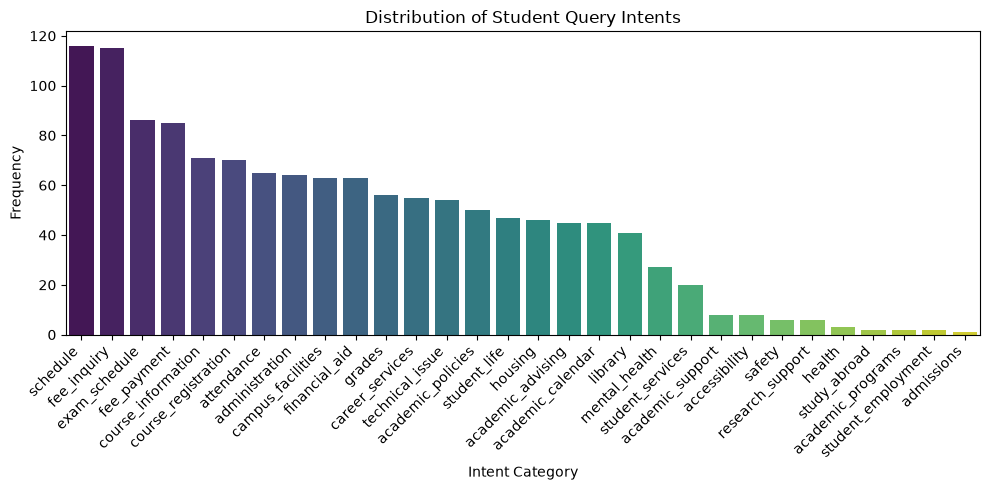

In [5]:
# 1. Check data types and non-null values
print('--- Dataset Info ---')
print(df.info())

# 2. Check for missing values
print('\n--- Missing Values Count ---')
print(df.isnull().sum())

# 3. Class balance / target distribution
print('\n--- Target Intent Counts ---')
print(df['Intent'].value_counts())

# 4. Visualize the target distribution (standard barplot)
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x='Intent',
    order=df['Intent'].value_counts().index,
    palette='viridis',
)
plt.title('Distribution of Student Query Intents')
plt.xlabel('Intent Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [6]:
# Drop rows where critical fields are null
df = df.dropna(subset=['User Message', 'Intent']).reset_index(drop=True)

# Encode categorical target variable (Intent) into integers
label_encoder = LabelEncoder()
df['Intent_Label'] = label_encoder.fit_transform(df['Intent'])

# Inspect the mapping dictionary
intent_mapping = dict(
    zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))
)
print('Target Classes Mapped:', intent_mapping)

Target Classes Mapped: {'academic_advising': np.int64(0), 'academic_calendar': np.int64(1), 'academic_policies': np.int64(2), 'academic_programs': np.int64(3), 'academic_support': np.int64(4), 'accessibility': np.int64(5), 'administration': np.int64(6), 'admissions': np.int64(7), 'attendance': np.int64(8), 'campus_facilities': np.int64(9), 'career_services': np.int64(10), 'course_information': np.int64(11), 'course_registration': np.int64(12), 'exam_schedule': np.int64(13), 'fee_inquiry': np.int64(14), 'fee_payment': np.int64(15), 'financial_aid': np.int64(16), 'grades': np.int64(17), 'health': np.int64(18), 'housing': np.int64(19), 'library': np.int64(20), 'mental_health': np.int64(21), 'research_support': np.int64(22), 'safety': np.int64(23), 'schedule': np.int64(24), 'student_employment': np.int64(25), 'student_life': np.int64(26), 'student_services': np.int64(27), 'study_abroad': np.int64(28), 'technical_issue': np.int64(29)}


In [7]:
# X is the predictor text feature, y is the encoded label
X = df['User Message']
y = df['Intent_Label']

print(f'Feature vector size: {X.shape}')
print(f'Target vector size: {y.shape}')

Feature vector size: (1322,)
Target vector size: (1322,)


In [9]:
# Filter out classes that have less than 2 samples
class_counts = df['Intent'].value_counts()
to_keep = class_counts[class_counts >= 2].index
df_filtered = df[df['Intent'].isin(to_keep)]

# Re-assign X and y using the filtered dataframe
X = df_filtered['User Message']
y = df_filtered['Intent_Label']

# Now you can safely use stratify=y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Training samples: 1056
Testing samples: 265


In [10]:
# Fit vectorizer only on training data; transform both train and test
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), max_features=3000, stop_words='english'
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f'Transformed Training Matrix Shape: {X_train_vec.shape}')
print(f'Transformed Testing Matrix Shape:  {X_test_vec.shape}')

Transformed Training Matrix Shape: (1056, 2544)
Transformed Testing Matrix Shape:  (265, 2544)


In [11]:
# Define candidate models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced'
    ),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Linear SVM': LinearSVC(class_weight='balanced', random_state=42),
}

# Train and evaluate accuracy for each
model_results = {}

for name, model in models.items():
  model.fit(X_train_vec, y_train)
  y_pred = model.predict(X_test_vec)
  acc = accuracy_score(y_test, y_pred)
  model_results[name] = acc
  print(f'{name} Accuracy: {acc * 100:.2f}%')

Logistic Regression Accuracy: 84.53%
Decision Tree Accuracy: 81.51%
Random Forest Accuracy: 83.77%
Linear SVM Accuracy: 89.81%


=== Classification Report ===

                     precision    recall  f1-score   support

  academic_advising       0.82      1.00      0.90         9
  academic_calendar       0.82      1.00      0.90         9
  academic_policies       0.78      0.70      0.74        10
   academic_support       0.50      0.50      0.50         2
      accessibility       1.00      0.50      0.67         2
     administration       0.71      0.77      0.74        13
         attendance       1.00      1.00      1.00        13
  campus_facilities       0.82      0.69      0.75        13
    career_services       1.00      0.82      0.90        11
 course_information       0.74      1.00      0.85        14
course_registration       1.00      0.79      0.88        14
      exam_schedule       0.81      1.00      0.89        17
        fee_inquiry       1.00      0.78      0.88        23
        fee_payment       0.85      1.00      0.92        17
      financial_aid       0.91      0.77      0.83   

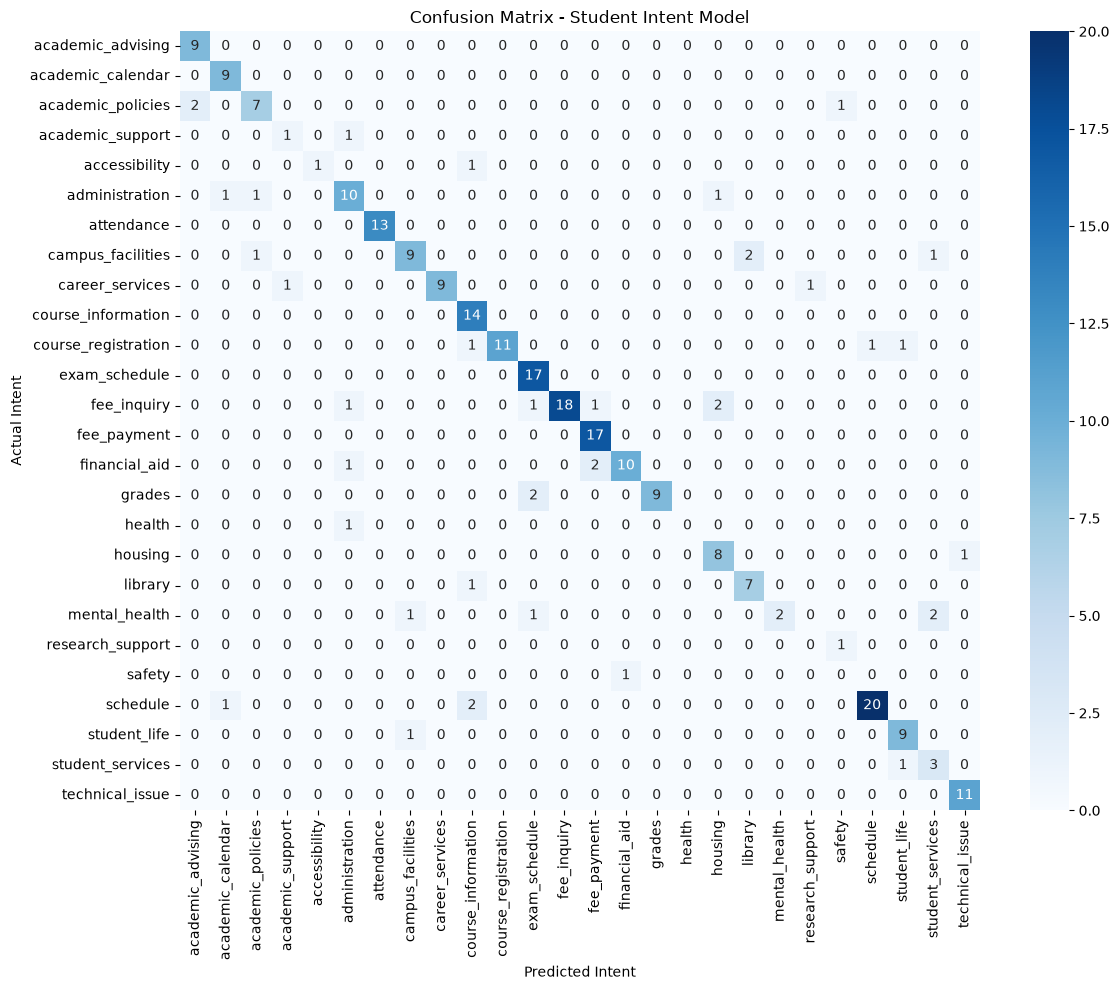

In [13]:
import numpy as np

best_model = models['Logistic Regression']
y_test_pred = best_model.predict(X_test_vec)

# Get the specific labels that are still present in our filtered test set
present_labels = np.unique(y_test)
present_names = label_encoder.inverse_transform(present_labels)

# 1. Full Classification Report
print('=== Classification Report ===\n')
print(classification_report(
    y_test, 
    y_test_pred, 
    labels=present_labels, 
    target_names=present_names
))

# 2. Confusion Matrix Heatmap
# We also update the confusion matrix to only plot the present classes
cm = confusion_matrix(y_test, y_test_pred, labels=present_labels)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=present_names, 
            yticklabels=present_names)
plt.title('Confusion Matrix - Student Intent Model')
plt.xlabel('Predicted Intent')
plt.ylabel('Actual Intent')
plt.tight_layout()
plt.show()

In [14]:
def predict_student_query(query_text):
  vec = vectorizer.transform([query_text])
  pred_label_idx = best_model.predict(vec)[0]
  predicted_intent = label_encoder.inverse_transform([pred_label_idx])[0]

  # Confidence score (using decision function or predict_proba)
  if hasattr(best_model, 'predict_proba'):
    confidence = np.max(best_model.predict_proba(vec)[0])
  else:
    confidence = 'N/A'

  return {'query': query_text, 'intent': predicted_intent, 'conf': confidence}


# Test samples
test_samples = [
    'How much do I need to pay for 3rd semester CSE?',
    'What is my class timing for tomorrow morning?',
    'I have 65% attendance, can I sit in exams?',
]

for sample in test_samples:
  print(predict_student_query(sample))

{'query': 'How much do I need to pay for 3rd semester CSE?', 'intent': 'fee_payment', 'conf': np.float64(0.08182566414542737)}
{'query': 'What is my class timing for tomorrow morning?', 'intent': 'schedule', 'conf': np.float64(0.08734617463887588)}
{'query': 'I have 65% attendance, can I sit in exams?', 'intent': 'attendance', 'conf': np.float64(0.39807889085081405)}


In [15]:
joblib.dump(best_model, 'student_intent_classifier.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')
joblib.dump(label_encoder, 'label_encoder.pkl')

print('All model artifacts exported successfully.')

All model artifacts exported successfully.
